# Comparing the H/D/A models

Which model should predict home win / draw / away win from the features that
`feature_importance` selected? This notebook fits every model in
`analysis.modeling.MODELS` the same way and compares them; `uv run modeling` prints
the same tables without the plots.

Run `uv run clean_data` first: it reads `model_frame.csv` from `settings.clean.out_dir`.

1. The setup: features, split, models
2. Walk-forward scores, pooled over 2021-2023
3. Season by season: is the ranking stable?
4. Calibration: do the probabilities mean what they say?
5. What the models predict: spread of the probabilities
6. Held out: 2024 onwards, scored once
7. Summary

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from money_printer_research.analysis.feature_importance import (
    CLASSES,
    SELECTED,
    TEST_FROM,
    VALID_SEASONS,
    columns,
    load,
    prior_score,
)
from money_printer_research.analysis.modeling import (
    MODELS,
    calibration,
    calibration_error,
    held_out,
    scores,
    walk_forward_predictions,
)
from money_printer_research.config import settings

pl.Config(float_precision=4, tbl_rows=40, fmt_str_lengths=40)
df = load(settings.clean.out_dir / "model_frame.csv")
COLS = columns(SELECTED)
# One fixed colour per model (categorical palette, in order), so every plot agrees.
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"], strict=True))

## 1. The setup

The features are the groups forward selection kept: Elo, the starters' form, games
in the last 14 days and the starters' previous minutes, each for both sides (plus the
difference where it has one). Each validation season is predicted by a model fitted
on the seasons before it only, so no model ever sees the future. The seasons from
`TEST_FROM` are held out until section 6.

In [2]:
season = pl.col("season_start")
print(f"{df.height} games; features: {SELECTED} ({len(COLS)} columns)")
print(f"validation seasons {VALID_SEASONS}, held out from {TEST_FROM}")
print("models:", list(MODELS))
df.group_by("season_start").agg(
    pl.len().alias("games"), *(pl.col("full_time_result").eq(c).mean().alias(c) for c in CLASSES)
).sort("season_start")

19761 games; features: ['elo', 'player_form90', 'games_14d_all', 'player_prev_min'] (12 columns)
validation seasons (2021, 2022, 2023), held out from 2024
models: ['logistic', 'logistic + sigmoid', 'boosted trees', 'poisson goals']


season_start,games,A,D,H
i32,u32,f64,f64,f64
2015,1826,0.2974,0.2590,0.4436
2016,1825,0.2822,0.2307,0.4871
2017,1826,0.3018,0.2448,0.4535
2018,1826,0.2941,0.2585,0.4474
2019,1725,0.3154,0.2435,0.4412
2020,1826,0.3467,0.2547,0.3987
2021,1826,0.3138,0.2585,0.4277
2022,1826,0.3001,0.2426,0.4573
2023,1752,0.3048,0.2643,0.4309


## 2. Walk-forward scores

Lower is better for every score but accuracy. Log loss is what feature selection
minimised. The ranked probability score (RPS) treats H, D, A as ordered, so calling
a home win a draw costs less than calling it an away win. The class prior (predict
every game with the training shares of H, D, A) is the floor any model has to beat.

The predictions are kept for the later sections.

In [3]:
preds = {name: walk_forward_predictions(df, model, COLS) for name, model in MODELS.items()}
y_valid = next(iter(preds.values()))[0]

prior = np.mean(
    [prior_score(df.filter(season < s), df.filter(season == s)) for s in VALID_SEASONS]
)
walk_forward = pl.DataFrame([{"model": n, **scores(y, p)} for n, (y, p) in preds.items()])
print(f"class prior log loss: {prior:.4f}")
walk_forward.sort("log_loss")

class prior log loss: 1.0725


model,log_loss,rps,brier,accuracy
str,f64,f64,f64,f64
"""logistic""",0.9813,0.1982,0.5839,0.5328
"""poisson goals""",0.9831,0.1984,0.5850,0.5320
"""logistic + sigmoid""",0.9835,0.1984,0.5852,0.5322
"""boosted trees""",0.9842,0.1986,0.5857,0.5300


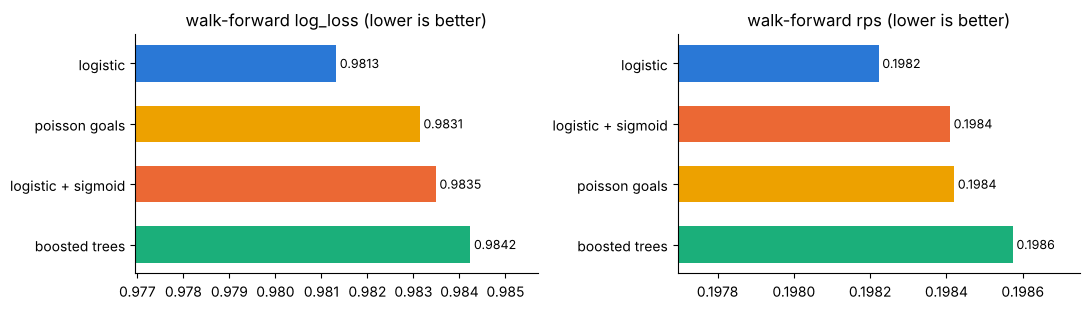

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, metric in zip(axes, ["log_loss", "rps"], strict=True):
    rows = walk_forward.sort(metric, descending=True)
    ax.barh(rows["model"], rows[metric], color=[COLORS[m] for m in rows["model"]], height=0.6)
    lo, hi = rows[metric].min(), rows[metric].max()
    ax.set_xlim(lo - (hi - lo) * 1.5, hi + (hi - lo) * 0.5)
    for i, v in enumerate(rows[metric]):
        ax.text(v, i, f" {v:.4f}", va="center", fontsize=9)
    ax.set_title(f"walk-forward {metric} (lower is better)")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

The axes are cut to the range of the models: the gaps are a few thousandths of log
loss, against about 0.09 between the class prior and any of them. All four models
get almost all of their skill from the same features; what differs is the last
detail.

## 3. Season by season

A pooled score can hide one lucky season. Here each validation season on its own,
as the gap to the logistic baseline in that season (above zero means worse than the
baseline).

In [5]:
# The predictions of section 2 are in season order; label each with its season.
seasons = df.filter(season.is_in(VALID_SEASONS)).sort("season_start")["season_start"].to_numpy()
per_season = pl.DataFrame(
    [
        {"model": n, "season": s, **scores(y[seasons == s], p[seasons == s])}
        for n, (y, p) in preds.items()
        for s in VALID_SEASONS
    ]
)
gap = per_season.with_columns(
    (pl.col("log_loss") - pl.col("log_loss").filter(pl.col("model") == "logistic").first())
    .over("season")
    .alias("vs_logistic")
)
gap.pivot("season", index="model", values="vs_logistic")

model,2021,2022,2023
str,f64,f64,f64
"""logistic""",0.0000,0.0000,0.0000
"""logistic + sigmoid""",0.0026,0.0011,0.0029
"""boosted trees""",0.0018,0.0009,0.0062
"""poisson goals""",0.0001,0.0013,0.0041


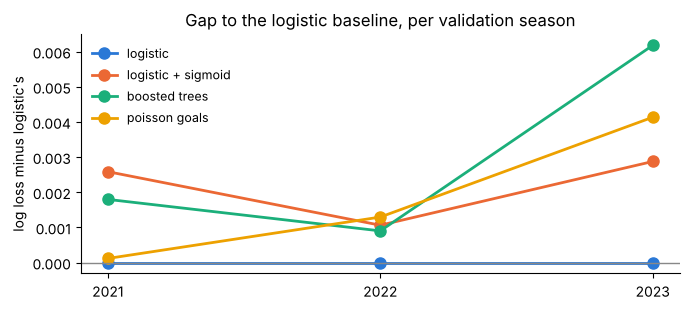

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for name in MODELS:
    rows = gap.filter(pl.col("model") == name)
    ax.plot(rows["season"], rows["vs_logistic"], marker="o", lw=2, ms=8, color=COLORS[name], label=name)
ax.axhline(0, color="#888", lw=1)
ax.set_xticks(list(VALID_SEASONS))
ax.set_ylabel("log loss minus logistic's")
ax.set_title("Gap to the logistic baseline, per validation season")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 4. Calibration

A forecast of 40% should come true about 40% of the time. Each class's predicted
probability is cut into deciles; each point is one decile, the mean predicted
probability against how often that outcome happened. On the diagonal is perfect.
The expected calibration error (ECE) is the games-weighted mean distance from it.

In [7]:
tables = {n: calibration(y, p) for n, (y, p) in preds.items()}
pl.concat(
    [calibration_error(t).with_columns(model=pl.lit(n)) for n, t in tables.items()]
).pivot("class", index="model", values="ece")

model,A,D,H
str,f64,f64,f64
"""logistic""",0.0107,0.0159,0.0173
"""logistic + sigmoid""",0.0110,0.0223,0.0233
"""boosted trees""",0.0093,0.0228,0.0167
"""poisson goals""",0.0193,0.0291,0.0198


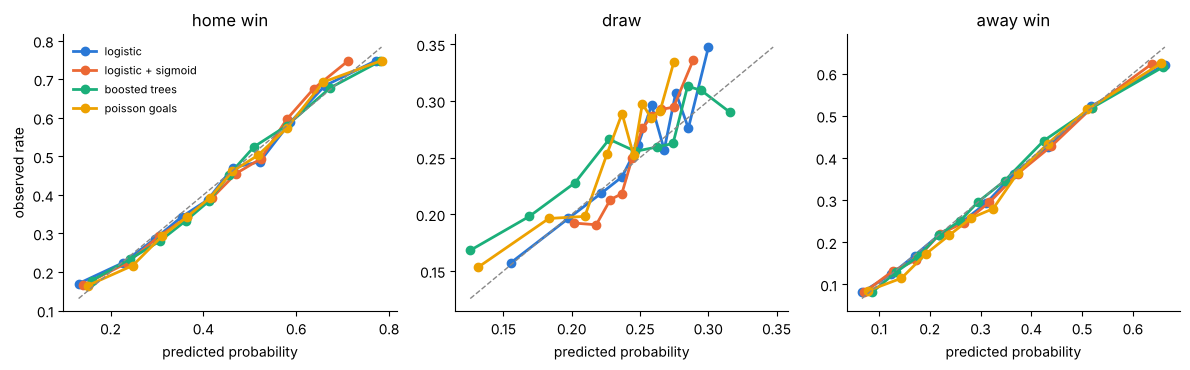

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=False)
for ax, c in zip(axes, ["H", "D", "A"], strict=True):
    lo, hi = 1.0, 0.0
    for name, table in tables.items():
        rows = table.filter(pl.col("class") == c)
        ax.plot(rows["predicted"], rows["observed"], marker="o", lw=2, ms=6, color=COLORS[name], label=name)
        lo, hi = min(lo, rows["predicted"].min(), rows["observed"].min()), max(hi, rows["predicted"].max(), rows["observed"].max())
    ax.plot([lo, hi], [lo, hi], color="#888", lw=1, ls="--")
    ax.set_title({"H": "home win", "D": "draw", "A": "away win"}[c])
    ax.set_xlabel("predicted probability")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("observed rate")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

## 5. What the models predict

How far the models move away from the average game. A model that is only cautious
keeps every game near the class shares; one that is confident spreads them out. The
draw is the hard one: its probability barely moves, so it is almost never the most
likely outcome.

model,sd P(H),sd P(D),sd P(A),predicts a draw
str,f64,f64,f64,i64
"""logistic""",0.1910,0.0424,0.1780,0
"""logistic + sigmoid""",0.1734,0.0256,0.1720,0
"""boosted trees""",0.1852,0.0576,0.1721,17
"""poisson goals""",0.1852,0.0424,0.1692,0


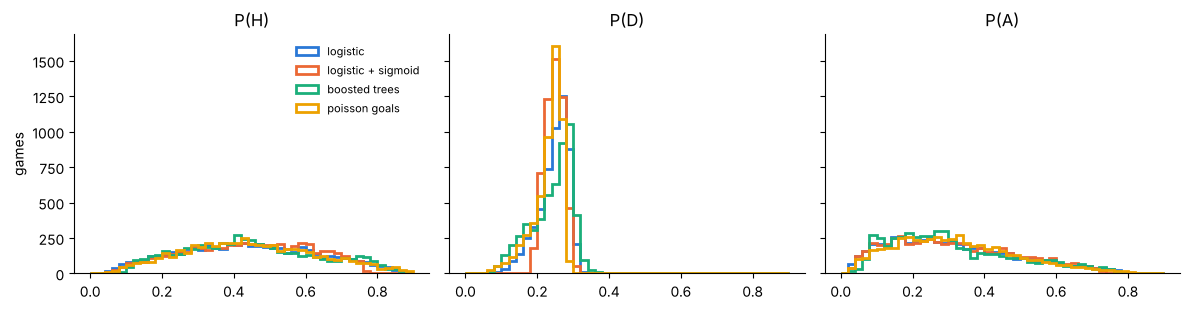

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
bins = np.linspace(0, 0.9, 46)
for ax, c in zip(axes, ["H", "D", "A"], strict=True):
    i = CLASSES.index(c)
    for name, (_, p) in preds.items():
        ax.hist(p[:, i], bins=bins, histtype="step", lw=2, color=COLORS[name], label=name)
    ax.set_title(f"P({c})")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("games")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

pl.DataFrame(
    [
        {
            "model": n,
            **{f"sd P({c})": float(p[:, CLASSES.index(c)].std()) for c in ["H", "D", "A"]},
            "predicts a draw": int((p.argmax(1) == CLASSES.index("D")).sum()),
        }
        for n, (_, p) in preds.items()
    ]
)

## 6. Held out

Every model fitted on all seasons before `TEST_FROM` and scored once on the rest.
This is a check, not a second selection round: choosing the model by these numbers
would turn the test seasons into validation seasons.

In [10]:
test = held_out(df)
test.sort("log_loss")

model,log_loss,rps,brier,accuracy
str,f64,f64,f64,f64
"""logistic""",0.9855,0.2005,0.5875,0.5241
"""poisson goals""",0.9865,0.2004,0.5880,0.5218
"""boosted trees""",0.9876,0.2010,0.5886,0.5198
"""logistic + sigmoid""",0.9877,0.2007,0.5888,0.5241


## 7. Summary

Built from the tables above, so it stays right when the data changes. `uv run modeling`
fits the chosen model on every season and saves it (see `settings.modeling.out_file`).

In [11]:
from IPython.display import Markdown


def ranking(table: pl.DataFrame) -> str:
    rows = table.sort("log_loss")
    return ", ".join(f"{m} {v:.4f}" for m, v in zip(rows["model"], rows["log_loss"], strict=True))


best = walk_forward.sort("log_loss")["model"][0]
best_test = test.sort("log_loss")["model"][0]
seasons_won = (
    per_season.sort("log_loss").group_by("season", maintain_order=True).first()
    .filter(pl.col("model") == best)["season"].sort().to_list()
)
ece = calibration_error(tables[best]).sort("class")
gap_to_prior = prior - walk_forward["log_loss"].max()
spread = walk_forward["log_loss"].max() - walk_forward["log_loss"].min()

Markdown(
    f"""
- **Walk-forward log loss** (lower is better): {ranking(walk_forward)}. **{best}** is best,
  and best in seasons {seasons_won} of {list(VALID_SEASONS)}.
- Every model beats the class prior ({prior:.4f}) by at least {gap_to_prior:.4f}; between
  the models the spread is {spread:.4f}.
- Calibration of {best} (ECE per class): {", ".join(f"{c} {e:.3f}" for c, e in ece.iter_rows())}.
- **Held out** from {TEST_FROM}: {ranking(test)}.
  {"It agrees with validation." if best_test == best else f"{best_test} is best there; the model stays the one chosen on validation."}
"""
)


- **Walk-forward log loss** (lower is better): logistic 0.9813, poisson goals 0.9831, logistic + sigmoid 0.9835, boosted trees 0.9842. **logistic** is best,
  and best in seasons [2021, 2022, 2023] of [2021, 2022, 2023].
- Every model beats the class prior (1.0725) by at least 0.0883; between
  the models the spread is 0.0029.
- Calibration of logistic (ECE per class): A 0.011, D 0.016, H 0.017.
- **Held out** from 2024: logistic 0.9855, poisson goals 0.9865, boosted trees 0.9876, logistic + sigmoid 0.9877.
  It agrees with validation.


What does not change with a rerun: the gaps between models are a few thousandths of log
loss, next to about 0.09 between any model and the prior, so the features carry the skill
and the model choice is detail. A recalibration only helps a model that is miscalibrated,
which the logistic regression is not. The Poisson goals model is worth keeping for what
the others cannot do: a full score distribution (exact score, over/under).